# Evolução das dicas geradas

Cada **rodada** é uma amostra de dicas geradas pelo caminho real da API (`uv run adia amostra-de-dicas`)
marcada à mão como serve/não serve. Treinar aqui é ajustar os papéis (`backend/adia/ia/subagentes/papeis.py`)
e o filtro de qualidade (`backend/adia/guarda/qualidade.py`) entre uma rodada e outra; o peso do modelo não muda.

Fluxo de uma rodada nova:

1. ajustar papel ou filtro e commitar;
2. `uv run adia amostra-de-dicas` grava `docs/relatorios/revisao-dicas-<data>.csv`;
3. preencher `serve (s/n)` e `comentario` na planilha;
4. reexecutar este caderno (`uv run --group notebook jupyter nbconvert --to notebook --execute --inplace ml/cadernos/evolucao-dicas.ipynb`).

Só entram as planilhas com todas as linhas marcadas.

In [1]:
import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

from adia.caminhos import encontrar_raiz
from adia.guarda.qualidade import motivo_de_pobreza
from adia.nucleo.itens.carregador import arquivos_de_itens, carregar
from adia.tipos import Nivel

RAIZ = encontrar_raiz()
PREFIXO = "dica gerada fora do padrão do nível: "
itens = {i.id: i for i in carregar(arquivos_de_itens(RAIZ / "data" / "itens")).itens}

rodadas = {}
for arquivo in sorted((RAIZ / "docs" / "relatorios").glob("revisao-dicas-*.csv")):
    with arquivo.open(encoding="utf-8-sig", newline="") as f:
        linhas = list(csv.DictReader(f, delimiter=";"))
    if linhas and all(l["serve (s/n)"].strip() in ("s", "n") for l in linhas):
        rodadas[arquivo.stem.removeprefix("revisao-dicas-")] = linhas
print(len(rodadas), "rodada(s) marcada(s):", ", ".join(rodadas))

4 rodada(s) marcada(s): 2026-11-03, 2026-11-04, 2026-11-04b, 2026-11-04c


## Placar por rodada

- **aproveitamento**: dicas que passam no filtro *e* servem, sobre o total gerado. É o que mais importa: dica gerada boa chegando ao estudante.
- **precisão**: das que passam, quantas servem. Dica ruim que passa chega ao estudante.
- **descarte indevido**: dicas boas barradas, que viram a pré-escrita (perde-se a adaptação, não a segurança).

In [2]:
def placar(linhas):
    passou = [l for l in linhas if l["filtro"] == "passou"]
    barrou = [l for l in linhas if l["filtro"] != "passou"]
    boas_que_passam = sum(l["serve (s/n)"] == "s" for l in passou)
    return {
        "geradas": len(linhas),
        "passaram": len(passou),
        "aproveitamento": boas_que_passam / len(linhas),
        "precisao": boas_que_passam / len(passou) if passou else 0.0,
        "ruins_que_passam": len(passou) - boas_que_passam,
        "descarte_indevido": sum(l["serve (s/n)"] == "s" for l in barrou),
    }

tabela = {nome: placar(linhas) for nome, linhas in rodadas.items()}
print(f"{'rodada':<12}{'geradas':>8}{'passaram':>9}{'aprov.':>8}{'precisão':>9}{'ruins ok':>9}{'desc. ind.':>11}")
for nome, p in tabela.items():
    print(f"{nome:<12}{p['geradas']:>8}{p['passaram']:>9}{p['aproveitamento']:>8.0%}{p['precisao']:>9.0%}"
          f"{p['ruins_que_passam']:>9}{p['descarte_indevido']:>11}")

rodada       geradas passaram  aprov. precisão ruins ok desc. ind.
2026-11-03        58       44     53%      70%       13          3
2026-11-04        61       43     49%      70%       13          5
2026-11-04b       61       46     46%      61%       18          0
2026-11-04c       61       43     48%      67%       14          0


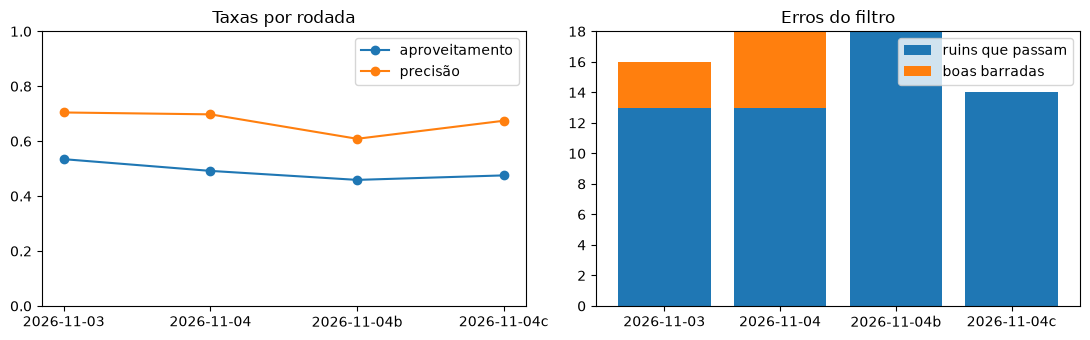

In [3]:
nomes = list(tabela)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.plot(nomes, [tabela[n]["aproveitamento"] for n in nomes], marker="o", label="aproveitamento")
a.plot(nomes, [tabela[n]["precisao"] for n in nomes], marker="o", label="precisão")
a.set_ylim(0, 1); a.set_title("Taxas por rodada"); a.legend()
b.bar(nomes, [tabela[n]["ruins_que_passam"] for n in nomes], label="ruins que passam")
b.bar(nomes, [tabela[n]["descarte_indevido"] for n in nomes],
      bottom=[tabela[n]["ruins_que_passam"] for n in nomes], label="boas barradas")
b.set_title("Erros do filtro"); b.legend()
fig.tight_layout()

## O filtro de hoje sobre todas as rodadas

Todas as linhas já marcadas formam um conjunto de regressão: o filtro atual é reaplicado a elas. Uma mudança no filtro
que piora alguma rodada antiga aparece aqui. Linhas barradas pela guarda de vazamento ficam de fora, porque o filtro de
qualidade não as vê.

In [4]:
def filtro_atual(l):
    return motivo_de_pobreza(l["gerada_pelo_modelo"], itens[l["item"]], Nivel[l["nivel"]])

for nome, linhas in rodadas.items():
    vistas = [l for l in linhas if not l["filtro"].startswith("guarda")]
    m = Counter((l["serve (s/n)"], filtro_atual(l) is None) for l in vistas)
    print(f"{nome}: boas que passam {m['s', True]}, ruins barradas {m['n', False]}, "
          f"ruins que passam {m['n', True]}, boas barradas {m['s', False]}")

2026-11-03: boas que passam 33, ruins barradas 12, ruins que passam 10, boas barradas 1
2026-11-04: boas que passam 35, ruins barradas 13, ruins que passam 10, boas barradas 0
2026-11-04b: boas que passam 28, ruins barradas 24, ruins que passam 7, boas barradas 0
2026-11-04c: boas que passam 29, ruins barradas 17, ruins que passam 12, boas barradas 0


## Motivos de descarte por rodada

In [5]:
for nome, linhas in rodadas.items():
    motivos = Counter(l["filtro"].removeprefix(PREFIXO) for l in linhas if l["filtro"] != "passou")
    print(nome, dict(motivos.most_common()))

2026-11-03 {'repete_o_enunciado': 5, 'sem_pergunta': 5, 'guarda descartou a dica gerada': 2, 'operacao_no_conceito': 1, 'curta': 1}
2026-11-04 {'repete_o_enunciado': 7, 'sem_pergunta': 4, 'guarda descartou a dica gerada': 3, 'inverte_a_operacao': 2, 'pergunta_fechada': 1, 'operacao_no_conceito': 1}
2026-11-04b {'sem_pergunta': 5, 'inverte_a_operacao': 3, 'repete_o_enunciado': 2, 'guarda descartou a dica gerada': 2, 'pergunta_fechada': 1, 'escreve_conta': 1, 'operacao_no_conceito': 1}
2026-11-04c {'sem_pergunta': 6, 'guarda descartou a dica gerada': 3, 'inverte_a_operacao': 3, 'pergunta_fechada': 2, 'operacao_no_conceito': 1, 'escreve_conta': 1, 'repete_o_enunciado': 1, 'numero_fora_do_enunciado': 1}


## O que ainda passa e não serve, na última rodada

É a lista de onde vem o próximo ajuste.

In [6]:
ultima = list(rodadas)[-1]
for l in rodadas[ultima]:
    if l["filtro"] == "passou" and l["serve (s/n)"] == "n":
        print(f"{l['n']:>3} {l['nivel']} {l['item']}: {l['comentario']}")

  3 L2 alg-eq-101: copia o material do RAG, longa e cortada no meio da frase; filtro deixou passar
  8 L2 alg-eq-102: ERRO: 'qual número subtraído de 5 resulta em 16' não é a equação
  9 L3 alg-eq-102: frase solta no gerúndio ('Anulando...'), não é instrução
 13 L2 alg-eq-103: L2 com 'desfazemos' e ordem errada (multiplicação primeiro); filtro deixou passar
 19 L2 alg-eq-104: tautológica, não ajuda
 28 L2 alg-eq-106: português quebrado: 'é a igualdade permanece'
 34 L2 alg-eq-107: vaga: 'seguir passos que mantêm a equação equivalente'
 38 L1 alg-eq-108: pergunta trivial
 47 L2 alg-eq-110: conceito impreciso: distributiva não 'desfaz a multiplicação dentro dos parênteses'
 48 L2 alg-eq-110: conceito impreciso, como a 47
 53 L2 alg-eq-111: segunda frase sem sujeito ('Organiza os dois membros')
 56 L3 alg-eq-111: palavra errada: 'desfie a distributiva'
 60 L3 alg-eq-112: ERRO MATEMÁTICO: 'desconsidera' os termos e troca os sinais; filtro deixou passar
 61 L3 alg-eq-112: confusa: 'desse la